# Mixed layers and their bounding inversions in all available soundings

Elevated mixed layers (smoothed dθ/dz ≤ 2.5 K/km, ≥ 400 m deep) above 850 hPa, and the stable
layers (dθ/dz ≥ 8 K/km) at their top and base, in R/V Revelle 2023, R/V Thompson (TGT) 2024,
Aminidivi (UWyo, 1979-2025) and IMD soundings. Layers are defined by potential temperature θ.

Inversion strength is Δθ over the 500 m above the mixed-layer top (or below its base), minus
the moist-adiabatic Δθ over the same 500 m (~2.5 K), so 0 means no stratification beyond moist adiabatic.

Functions: `inversions.jl` (tests in `test_inversions.jl`), readers: `sonde_profiles.jl`.

In [1]:
cd(joinpath(homedir(), "projects/ASTRAL/soundings/src/"))
using Pkg; Pkg.activate("..")

using Dates, Statistics, Printf
using CSV, DataFrames, NCDatasets
using PythonPlot

include(abspath("sonde_profiles.jl"))   # readers, dθdz_moist; includes inversions.jl
using .Inversions

  Activating project at `~/projects/ASTRAL/soundings`


In [2]:
# read every sounding (Revelle 2023, TGT 2024, Amini 1979-2025, IMD 2023-2024); ~2 min
profs, failures = all_profiles()
println(length(profs), " profiles read; ", length(failures), " unreadable or nearly empty")

┌ Warning: CSV: 1 parse problem in <GenericIOBuffer>; first: long_row at data row 1, column 0: expected 11 fields, found 12 (extra fields ignored). Inspect CSV.problems(file); pass on_error=:collect to silence this warning or on_error=:error to throw.
└ @ CSV /home/deszoeks/.julia/packages/CSV/E5gMM/src/core.jl:2984


4502 profiles read; 33 unreadable or nearly empty


┌ Warning: JSON-RPC endpoint has been blocked writing to its peer; outgoing messages are queueing up and will not be delivered until the peer resumes reading
│   blocked_seconds = 74.0
│   queued_messages = 1
└ @ VSCodeServer.JSONRPC /home/deszoeks/.vscode-server/extensions/julialang.language-julia-1.249.2/scripts/packages/JSONRPC/src/core.jl:414


In [3]:
# mixed layers above 850 hPa in every sounding, with their top and base inversions
nfree_min = 8   # levels between 850 hPa and 7 km needed to resolve layers
"one row per mixed layer (depth ≥ 400 m, base above 850 hPa, top below zmax)"
function ml_table(profs; zmax=7000.0, kw...)
    rows = NamedTuple[]
    for (n, s) in enumerate(profs)
        (isfinite(s.z850) && s.nfree >= nfree_min) || continue
        for m in find_mixed_layers(s.z, s.θ; zlims=(s.z850, 9000.0), kw...)
            m.ml_t <= zmax || continue
            # inversion strength in excess of the moist adiabat over the same 500 m
            moistΔθ(zc) = 500 * dθdz_moist(interp1(s.z, s.θ, [zc])[1], interp1(s.z, s.p, [zc])[1])
            exc = (top_exc = m.top_Δθ500 - moistΔθ(m.ml_t + 250), base_exc = m.base_Δθ500 - moistΔθ(m.ml_b - 250))
            push!(rows, merge((n=n, source=s.source, station=s.station, time=s.time, lat=s.lat, lon=s.lon), m, exc))
        end
    end
    DataFrame(rows)
end
mltab = ml_table(profs)
# primary mixed layer: the deepest one with its top at 3-6 km
mlprim = combine(groupby(filter(r -> 3000 <= r.ml_t <= 6000, mltab), :n), sdf -> sdf[argmax(sdf.mld), :])

# summary by source / station
prof_df = DataFrame(n=eachindex(profs), source=[p.source for p in profs], station=[p.station for p in profs],
                    resolved=[isfinite(p.z850) && p.nfree >= nfree_min for p in profs])
# medians over soundings with a primary mixed layer, ignoring NaN (no inversion found / no data)
fmed(x) = (y = filter(isfinite, collect(skipmissing(x))); isempty(y) ? NaN : median(y))
summ = combine(groupby(leftjoin(prof_df, mlprim, on=[:n, :source, :station]), [:source, :station]),
    nrow => :N, :resolved => sum => :Nres, :mld => (x -> count(!ismissing, x)) => :Nml,
    [:mld, :resolved] => ((m, r) -> count(!ismissing, m)/max(1, sum(r))) => :fml,
    :base_b => fmed => :base_b, :ml_b => fmed => :ml_b, :ml_t => fmed => :ml_t, :top_t => fmed => :top_t,
    :base_Δθ500 => fmed => :base_Δθ500, :top_Δθ500 => fmed => :top_Δθ500,
    :base_exc => fmed => :base_exc, :top_exc => fmed => :top_exc,
    :base_b => (x -> count(isfinite, skipmissing(x))) => :Nbase_inv, :top_t => (x -> count(isfinite, skipmissing(x))) => :Ntop_inv)
summ

Row,source,station,N,Nres,Nml,fml,base_b,ml_b,ml_t,top_t,base_Δθ500,top_Δθ500,base_exc,top_exc,Nbase_inv,Ntop_inv
,String,String,Int64,Int64,Int64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Int64,Int64
1,Revelle,Revelle,36,36,26,0.722222,2294.0,2987.0,4195.94,5084.56,2.98914,5.28788,0.0617988,2.65614,19,22
2,TGT,TGT,199,198,57,0.287879,2748.59,3003.39,3822.37,4318.97,2.59177,2.39299,-0.526909,-0.423678,31,32
3,Amini,Amini,3022,2100,712,0.339048,2732.0,3221.0,4225.0,5008.0,2.47644,2.83096,-0.410111,0.288576,212,298
4,IMD,ahmedabad,137,137,108,0.788321,2310.72,2454.44,4412.52,4899.8,1.97701,2.84887,-1.02818,0.325626,38,75
5,IMD,bhubaneswar,60,60,34,0.566667,2050.34,2564.0,3843.55,4605.39,2.18595,2.3526,-0.89267,-0.422483,8,16
6,IMD,chennai,112,111,75,0.675676,2505.3,2516.45,3895.8,4630.83,2.33165,2.57521,-0.711839,-0.151063,31,42
7,IMD,karaikal,133,132,79,0.598485,2303.57,2976.6,3925.68,4550.15,2.28118,2.84241,-0.683941,0.0992911,36,50
8,IMD,kochi,132,132,54,0.409091,2943.46,3339.04,4031.53,4621.07,2.78554,2.53516,-0.169499,-0.143092,30,28
9,IMD,kolkata,126,126,97,0.769841,1767.8,1725.5,3938.62,4600.14,1.91241,2.98663,-1.11757,0.336413,27,70


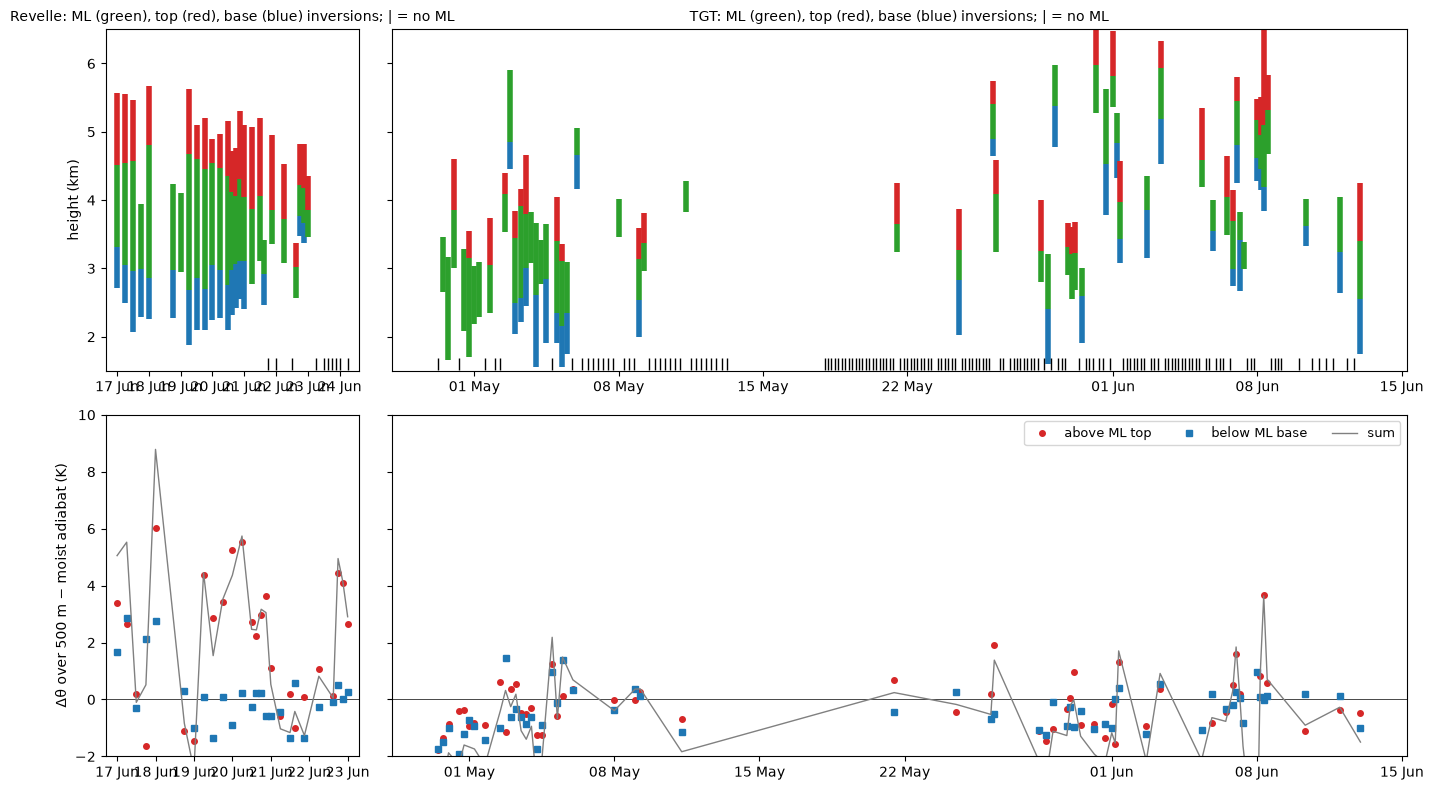

In [4]:
# time series of the primary mixed layer and its bounding inversions on the two ships
clf()
fig, axs = subplots(2, 2, figsize=(14, 8), sharey="row", gridspec_kw=Dict("width_ratios"=>[1, 4]))
for (k, src) in enumerate(("Revelle", "TGT"))
    m = sort(filter(r -> r.source == src, mlprim), :time)
    t = m.time
    ax = axs[0, k-1]
    for r in eachrow(m)
        ax.plot([r.time, r.time], [r.ml_b, r.ml_t]/1e3, color="tab:green", lw=4, solid_capstyle="butt")
        isfinite(r.top_t)  && ax.plot([r.time, r.time], [r.ml_t, r.top_t]/1e3, color="tab:red", lw=4, solid_capstyle="butt")
        isfinite(r.base_b) && ax.plot([r.time, r.time], [r.base_b, r.ml_b]/1e3, color="tab:blue", lw=4, solid_capstyle="butt")
    end
    # soundings without a mixed layer at 3-6 km
    tall = [p.time for p in profs if p.source == src]
    ax.plot(setdiff(tall, t), fill(1.6, length(setdiff(tall, t))), "k|", ms=8)
    ax.set_ylim(1.5, 6.5); ax.set_title("$src: ML (green), top (red), base (blue) inversions; | = no ML", fontsize=10)
    ax.xaxis.set_major_formatter(PythonPlot.matplotlib.dates.DateFormatter("%d %b"))
    ax = axs[1, k-1]
    ax.axhline(0, color="k", lw=0.5)
    ax.plot(t, m.top_exc, "o", color="tab:red", ms=4, label="above ML top")
    ax.plot(t, m.base_exc, "s", color="tab:blue", ms=4, label="below ML base")
    ax.plot(t, m.top_exc .+ m.base_exc, "-", color="gray", lw=1, label="sum")
    ax.set_ylim(-2, 10)
    ax.xaxis.set_major_formatter(PythonPlot.matplotlib.dates.DateFormatter("%d %b"))
end
axs[0,0].set_ylabel("height (km)"); axs[1,0].set_ylabel("Δθ over 500 m − moist adiabat (K)"); axs[1,1].legend(fontsize=9, ncol=3)
tight_layout()

gcf()

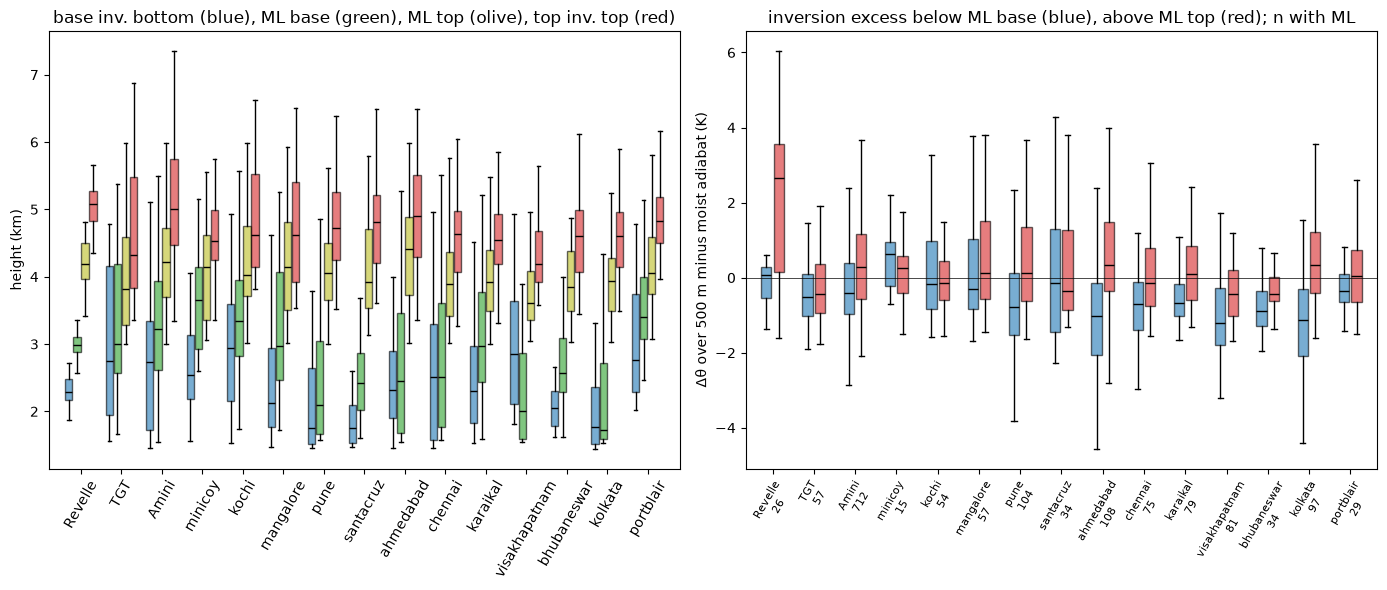

In [5]:
# distributions of mixed-layer and inversion heights and strengths by source / station
groups = [("Revelle",), ("TGT",), ("Amini",), ("IMD", "minicoy"), ("IMD", "kochi"), ("IMD", "mangalore"),
          ("IMD", "pune"), ("IMD", "santacruz"), ("IMD", "ahmedabad"), ("IMD", "chennai"), ("IMD", "karaikal"),
          ("IMD", "visakhapatnam"), ("IMD", "bhubaneswar"), ("IMD", "kolkata"), ("IMD", "portblair")]
sel(g) = filter(r -> r.source == g[1] && (length(g) == 1 || r.station == g[2]), mlprim)
labels = [length(g) == 1 ? g[1] : g[2] for g in groups]
fin(x) = filter(isfinite, collect(x))
clf()
fig, axs = subplots(1, 2, figsize=(14, 6))
ax = axs[0]
for (k, g) in enumerate(groups)
    m = sel(g)
    for (x, col, dx) in ((m.base_b, "tab:blue", -0.3), (m.ml_b, "tab:green", -0.1), (m.ml_t, "tab:olive", 0.1), (m.top_t, "tab:red", 0.3))
        y = fin(x) ./ 1e3
        isempty(y) && continue
        ax.boxplot([y], positions=[k + dx], widths=0.18, showfliers=false, patch_artist=true,
                   boxprops=Dict("facecolor"=>col, "alpha"=>0.6), medianprops=Dict("color"=>"k"))
    end
end
ax.set_xticks(1:length(groups)); ax.set_xticklabels(labels, rotation=60)
ax.set_ylabel("height (km)"); ax.set_title("base inv. bottom (blue), ML base (green), ML top (olive), top inv. top (red)")
ax = axs[1]
for (k, g) in enumerate(groups)
    m = sel(g)
    for (x, col, dx) in ((m.base_exc, "tab:blue", -0.15), (m.top_exc, "tab:red", 0.15))
        y = fin(x); isempty(y) && continue
        ax.boxplot([y], positions=[k + dx], widths=0.25, showfliers=false, patch_artist=true,
                   boxprops=Dict("facecolor"=>col, "alpha"=>0.6), medianprops=Dict("color"=>"k"))
    end
end
ax.set_xticks(1:length(groups)); ax.set_xticklabels([l * "\n" * string(nrow(sel(g))) for (l, g) in zip(labels, groups)], rotation=60, fontsize=8)
ax.axhline(0, color="k", lw=0.5)
ax.set_ylabel("Δθ over 500 m minus moist adiabat (K)"); ax.set_title("inversion excess below ML base (blue), above ML top (red); n with ML")
tight_layout()

gcf()